# EXP-004 — SVM mặc định

**Người thực hiện** Mai  
**Ngày chạy lại** 18/11/2026

## Mục tiêu

Đánh giá khả năng nhận diện stress của SVM mặc định trên người chưa xuất hiện trong tập huấn luyện. Giả thuyết là SVM với kernel RBF có thể đạt Macro-F1 cao hơn LR và KNN mặc định trên cùng bộ đặc trưng.

## Dữ liệu và phương pháp

Bộ physiological68 gồm 6.189 cửa sổ từ 15 người, mỗi cửa sổ có 68 đặc trưng sinh lý. Bài toán nhị phân phân biệt Stress và Non-stress. Bài toán ba lớp phân biệt Baseline, Stress và Amusement.

Mỗi fold LOSO train trên 14 người và test trên một người. Median imputer và StandardScaler được fit trong tập train của từng fold. SVM dùng `SVC(kernel="rbf", C=1.0, gamma="scale")`. Cấu hình G3 giữ seed 42, không tuning hay cân bằng lớp. Đường dẫn bảng đặc trưng, schema và SHA-256 nằm trong [config.yaml](config.yaml).

In [1]:
from pathlib import Path
import json
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

here = Path.cwd()
repo = next(path for path in (here, *here.parents) if (path / "scripts/run_g3_baselines.py").is_file())
experiment = repo / "experiments/01_baselines/EXP-004_SVM"
config_file = experiment / "config.yaml"
config = yaml.safe_load(config_file.read_text(encoding="utf-8"))
output = repo / config["output_dir"]
keys = ["task", "subject_id"]
metrics = ["macro_f1", "balanced_accuracy"]
task_names = {"binary": "Nhị phân", "multiclass": "Ba lớp"}

print("Dữ liệu:", config["features"])
print("SHA-256:", config["feature_sha256"])
print("Schema:", config["schema"])


Dữ liệu: data/features/g2_physiological68_group15_20261107/all_subjects.csv
SHA-256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
Schema: data/features/g2_physiological68_group15_20261107/feature_schema.json


## Lần 1 — Kết quả G3 đã lưu

Điểm SVM lịch sử được dùng làm mốc đối chiếu cho lần huấn luyện lại. Bảng dưới là điểm trung bình và độ lệch chuẩn mẫu theo 15 người cho từng bài toán. [Báo cáo G3](../../../docs/G3_TONG_HOP.md)

In [2]:
g3_file = repo / "reports/g3_group/metrics_by_subject.csv"
g3 = pd.read_csv(g3_file)
historical = g3.loc[g3["model"].eq("svm")].copy()
assert len(historical) == 30 and not historical.duplicated(keys).any()
display(historical.groupby("task")[metrics].agg(["mean", "std"]).round(4))


macro_f1         balanced_accuracy        
               mean     std              mean     std
task                                                 
binary       0.8424  0.1805            0.8663  0.1575
multiclass   0.6177  0.1647            0.6595  0.1559

## Lần 2 — Huấn luyện lại

Lượt này dùng runner G3 và thư mục kết quả riêng `outputs/exp004_svm_full/`. Hồ sơ của lượt chạy lưu tham số, môi trường, snapshot mã nguồn và dự đoán ngoài mẫu.

In [ ]:
RUN_TRAIN = False
command = [
    str(repo / ".venv-g1/Scripts/python.exe"), "-X", "utf8",
    "scripts/run_g3_baselines.py", "--config", str(config_file), "--resume",
]
if RUN_TRAIN:
    subprocess.run(command, cwd=repo, check=True)

verification = json.loads((output / "verification.json").read_text(encoding="utf-8"))
assert verification["status"] == "passed" and verification["scope"] == "main"
assert verification["models"] == ["svm"] and verification["n_folds"] == 30
assert verification["n_predictions"] == 12378
assert verification["data_sha256"] == config["feature_sha256"]

results = pd.read_csv(output / "verified_metrics_by_subject.csv")
assert set(results["model"]) == {"svm"}
assert len(results) == 30 and not results.duplicated(keys).any()
assert set(results["task"]) == set(task_names)
assert all(set(rows["subject_id"]) == set(config["expected_subjects"]) for _, rows in results.groupby("task"))
results.to_csv(experiment / "results.csv", index=False)

manifest = json.loads((output / "config.json").read_text(encoding="utf-8"))
environment = json.loads((output / "environment.json").read_text(encoding="utf-8"))
print("Trạng thái: rerun — xác minh đạt 30 fold")
print("Git commit:", manifest.get("git_commit") or "Chưa xác minh")
print("SHA-256 mã nguồn:", verification["code_sha256"])
display(environment)
display(results[keys + metrics].sort_values(keys).round(4))
display(results.groupby("task")[metrics].agg(["mean", "std"]).round(4))


Trạng thái: rerun — xác minh đạt 30 fold
Git commit: Chưa xác minh
SHA-256 mã nguồn: 05772dd832acf58138eda927c7dbf2f7ba7239d6c596a09e7397d1c730a550f6


{'python': '3.12.14 (main, Sep 29 2026, 15:00:58) [MSC v.1944 64 bit (AMD64)]',
 'packages': {'numpy': '2.5.4',
  'pandas': '3.1.0',
  'PyYAML': '6.0.3',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'imbalanced-learn': '0.14.2'}}

,task,subject_id,macro_f1,balanced_accuracy
15,binary,S10,1.0000,1.0000
16,binary,S11,0.8971,0.9330
17,binary,S13,0.6488,0.7509
18,binary,S14,0.9884,0.9841
19,binary,S15,0.7676,0.7459
20,binary,S16,0.8361,0.8897
21,binary,S17,0.9391,0.9304
22,binary,S2,0.5543,0.5717
23,binary,S3,0.9571,0.9481
24,binary,S4,0.9850,0.9862


macro_f1         balanced_accuracy        
               mean     std              mean     std
task                                                 
binary       0.8424  0.1805            0.8663  0.1575
multiclass   0.6177  0.1647            0.6595  0.1559

## Đối chiếu và phân tích

Chênh lệch giữa hai lượt được tính trên cùng người test và cùng bài toán. LR và KNN trong bảng so sánh lấy từ G3. Đường biểu diễn bên dưới cho thấy mức biến thiên của SVM theo người tham gia.

Fold có điểm khác G3: 0/30


macro_f1  balanced_accuracy
task       model                             
binary     knn      0.7258             0.7541
           lr       0.8103             0.8304
           svm      0.8424             0.8663
multiclass knn      0.5555             0.5753
           lr       0.5894             0.6315
           svm      0.6177             0.6595

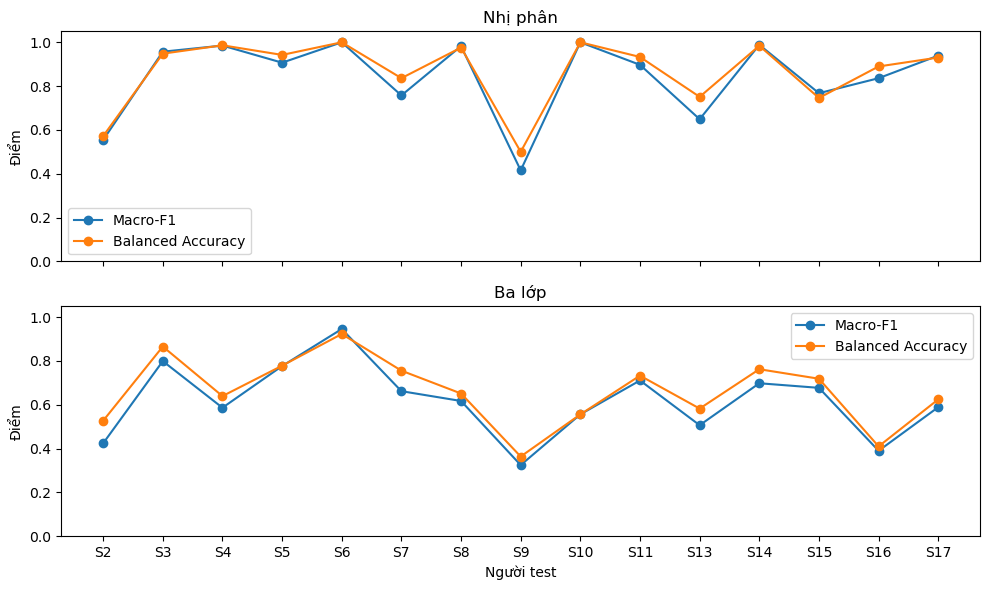

In [4]:
paired = historical[keys + metrics].merge(
    results[keys + metrics], on=keys, suffixes=("_g3", "_rerun"), validate="one_to_one"
)
assert len(paired) == 30
for metric in metrics:
    paired[f"{metric}_delta"] = paired[f"{metric}_rerun"] - paired[f"{metric}_g3"]
delta = paired[[f"{metric}_delta" for metric in metrics]]
changed = ~np.isclose(delta, 0, atol=1e-10, rtol=0).all(axis=1)
print(f"Fold có điểm khác G3: {changed.sum()}/30")
if changed.any():
    display(paired.loc[changed])

baseline = g3.loc[g3["model"].isin(["knn", "lr"])]
comparison = pd.concat([baseline, results]).groupby(["task", "model"])[metrics].mean()
display(comparison.round(4))

figures = experiment / "figures"
figures.mkdir(exist_ok=True)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True)
subjects = sorted(config["expected_subjects"], key=lambda subject: int(subject[1:]))
for ax, (task, name) in zip(axes, task_names.items()):
    points = results.loc[results["task"].eq(task)].set_index("subject_id").loc[subjects, metrics]
    points.rename(columns=dict(zip(metrics, ["Macro-F1", "Balanced Accuracy"]))).plot(ax=ax, marker="o")
    ax.set_title(name)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Điểm")
axes[-1].set_xticks(range(len(subjects)), subjects)
axes[-1].set_xlabel("Người test")
fig.tight_layout()
fig.savefig(figures / "svm_metrics_by_subject.png", dpi=150)
plt.show()


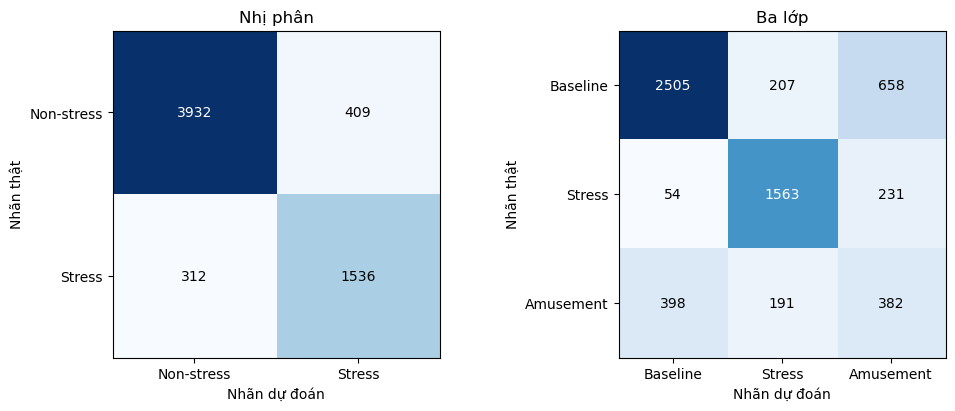

In [5]:
run_summary = json.loads((output / "summary.json").read_text(encoding="utf-8"))
label_names = {"binary": ["Non-stress", "Stress"], "multiclass": ["Baseline", "Stress", "Amusement"]}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (task, name) in zip(axes, task_names.items()):
    summary = next(row for row in run_summary["results"] if row["task"] == task)
    matrix = np.asarray(summary["confusion_matrix"])
    labels = label_names[task]
    ax.imshow(matrix, cmap="Blues")
    for (row, col), count in np.ndenumerate(matrix):
        ax.text(col, row, str(count), ha="center", va="center",
                color="white" if count > matrix.max() / 2 else "black")
    ax.set_xticks(range(len(labels)), labels)
    ax.set_yticks(range(len(labels)), labels)
    ax.set(title=name, xlabel="Nhãn dự đoán", ylabel="Nhãn thật")
fig.savefig(figures / "svm_confusion_matrices.png", dpi=150)
plt.show()


In [6]:
from IPython.display import Markdown

lines = ["## Kết luận", ""]
for task, name in task_names.items():
    table = comparison.loc[task]
    svm = table.loc["svm"]
    differences = svm["macro_f1"] - table["macro_f1"]
    weakest = results.loc[results["task"].eq(task)].nsmallest(1, "macro_f1").iloc[0]
    lines.append(
        f"- **{name}** — SVM đạt Macro-F1 **{svm['macro_f1']:.4f}** và "
        f"Balanced Accuracy **{svm['balanced_accuracy']:.4f}**. "
        f"Chênh lệch Macro-F1 so với LR là **{differences['lr']:+.4f}** "
        f"và so với KNN là **{differences['knn']:+.4f}**. "
        f"Điểm Macro-F1 thấp nhất thuộc {weakest['subject_id']} ({weakest['macro_f1']:.4f})."
    )
lines += ["", f"Có **{changed.sum()}/30 fold** khác về điểm so với G3 theo ngưỡng tuyệt đối 1e-10. "
          "Kết quả theo người cho thấy hiệu quả nhận diện thay đổi giữa các đối tượng. "
          "Cấu hình này là mốc so sánh cho SVM tuning ở EXP-008."]
display(Markdown("\n".join(lines)))


## Kết luận

- **Nhị phân** — SVM đạt Macro-F1 **0.8424** và Balanced Accuracy **0.8663**. Chênh lệch Macro-F1 so với LR là **+0.0321** và so với KNN là **+0.1165**. Điểm Macro-F1 thấp nhất thuộc S9 (0.4154).
- **Ba lớp** — SVM đạt Macro-F1 **0.6177** và Balanced Accuracy **0.6595**. Chênh lệch Macro-F1 so với LR là **+0.0283** và so với KNN là **+0.0622**. Điểm Macro-F1 thấp nhất thuộc S9 (0.3248).

Có **0/30 fold** khác về điểm so với G3 theo ngưỡng tuyệt đối 1e-10. Kết quả theo người cho thấy hiệu quả nhận diện thay đổi giữa các đối tượng. Cấu hình này là mốc so sánh cho SVM tuning ở EXP-008.